# 05 · Inferencia sobre el set de prueba
### Ingrid Carolina Ortíz Mejicanos
Se carga el **pipeline completo** (`models/pipeline_completo.pkl`: preprocesamiento + LightGBM) y se predice `item_cnt_month` para los **214,200 pares tienda-producto de noviembre 2015** (`date_block_num = 34`), un mes que el modelo no ha visto.
Resultado: `reports/predicciones_test.csv` con las columnas **ID** e **item_cnt_month** (formato de envío de Kaggle).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW, MODELS, REPORTS = ROOT / "data" / "raw", ROOT / "models", ROOT / "reports"
FIGS = REPORTS / "figures"
sys.path.insert(0, str(ROOT))
from predict_future_sales_eda.features import limpiar_ventas, MAPA_TIENDAS

sns.set_theme(style="whitegrid", palette="deep")
pipeline_completo = joblib.load(MODELS / "pipeline_completo.pkl")
with open(MODELS / "modelo_ganador.json", encoding="utf-8") as f:
    print("Modelo dentro del pipeline:", json.load(f))
print("Pasos:", [n for n, _ in pipeline_completo.steps])

2026-11-25 00:40:59.621 -06:00 | INFO     | predict_future_sales_eda.config:<module>:11 - PROJ_ROOT path is: C:\Users\icome\Documents\predict-future-sales-eda_parte2


Modelo dentro del pipeline: {'modelo': 'LightGBM #3', 'parametros': "{'n_estimators': 800, 'learning_rate': 0.03, 'num_leaves': 127, 'min_child_samples': 50, 'colsample_bytree': 0.8}", 'rmse_valid': 0.8199917563384319}
Pasos: ['rezagos', 'imputacion_categorica', 'imputacion_numerica_mediana', 'imputacion_numerica_cero', 'outliers_iqr', 'outliers_percentil', 'transformacion_log', 'mapper_mes', 'target_encoding', 'one_hot', 'eliminar', 'escalado', 'modelo']


In [2]:
test = pd.read_csv(RAW / "test.csv")
test["date_block_num"] = 34
print(f"Pares tienda-producto a predecir: {len(test):,}")
test.head()

Pares tienda-producto a predecir: 214,200


,ID,shop_id,item_id,date_block_num
0,0,5,5037,34
1,1,5,5320,34
2,2,5,5233,34
3,3,5,5232,34
4,4,5,5268,34


In [3]:
pred = pipeline_completo.predict(test[["shop_id", "item_id", "date_block_num"]])
submission = pd.DataFrame({"ID": test["ID"], "item_cnt_month": pred})
print("Filas:", len(submission), "| IDs únicos:", submission["ID"].nunique(), "| nulos:", int(submission["item_cnt_month"].isna().sum()))
print(f"Rango de predicciones: [{submission['item_cnt_month'].min():.3f}, {submission['item_cnt_month'].max():.3f}]")
submission["item_cnt_month"].describe(percentiles=[0.5, 0.9, 0.99]).round(3).to_frame().T

Filas: 214200 | IDs únicos: 214200 | nulos: 0
Rango de predicciones: [0.000, 20.000]


,count,mean,std,min,50%,90%,99%,max
item_cnt_month,214200.0,0.275,0.781,0.0,0.077,0.585,3.445,20.0



- Se predijeron los **214,200 pares** del test, con **214,200 IDs únicos** y **0 nulos**.
- Todas las predicciones están en el rango **[0, 20]**, gracias al paso final del pipeline (`RegresorAcotado`), igual que la evaluación de Kaggle.
- La distribución es muy asimétrica, como la variable real: la **mediana es 0.077**, el **90 %** de los pares tiene predicción menor que **0.59** y solo el **1 %** supera **3.4** unidades. La media (**0.275**) queda cerca de la media de la venta real en los meses de entrenamiento. El modelo reproduce que la mayoría de pares vende 0 o casi 0 en un mes, y que pocos pares concentran las ventas.

## Revisión de coherencia
Como no se conocen las ventas reales de noviembre, se revisa que las predicciones tengan sentido: por **segmento de cobertura** (los mismos del EDA, sección 10) y comparando con las ventas de **octubre 2015**.

,pares,prediccion_media,unidades_totales
segmento,,,
Par con historial,111471,0.385,42887.032
"Producto conocido, nuevo en esa tienda",87483,0.060,5270.082
Producto nuevo,15246,0.712,10849.385


Unidades de octubre 2015 (pares del test, acotadas a 20): 54,760
Unidades predichas para noviembre 2015:                 59,006
Correlación predicción vs venta de octubre: 0.732


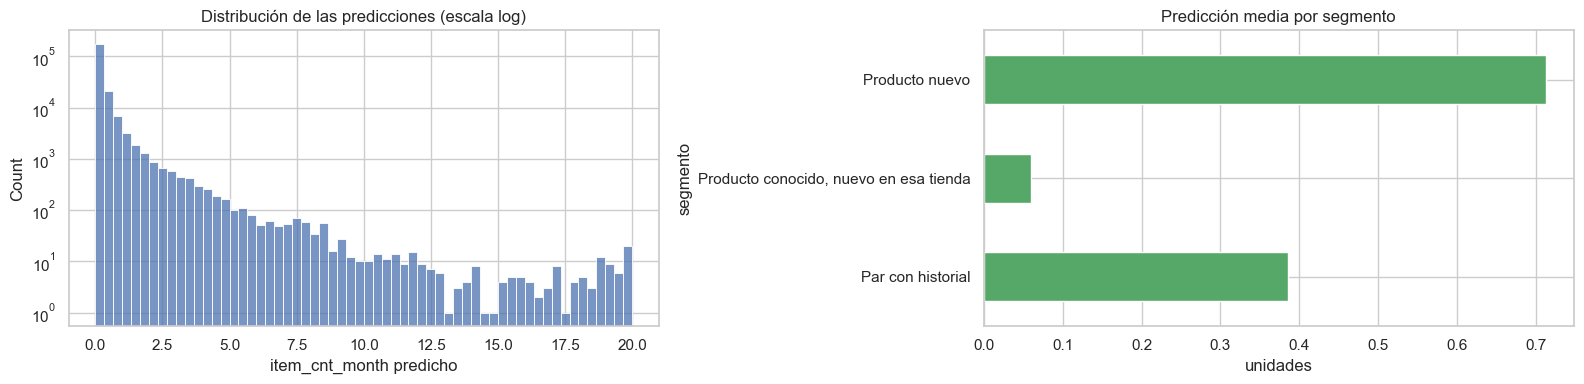

In [4]:
ventas = limpiar_ventas(pd.read_csv(RAW / "sales_train.csv"))
pares_hist = ventas[["shop_id", "item_id"]].drop_duplicates().assign(par_con_historia=True)
t = test.copy()
t["shop_id"] = t["shop_id"].replace(MAPA_TIENDAS)
t = t.merge(pares_hist, on=["shop_id", "item_id"], how="left")
t["segmento"] = np.select([t["par_con_historia"].notna(), t["item_id"].isin(ventas["item_id"])], ["Par con historial", "Producto conocido, nuevo en esa tienda"], "Producto nuevo")
t["pred"] = pred
resumen = t.groupby("segmento")["pred"].agg(pares="size", prediccion_media="mean", unidades_totales="sum").round(3)
display(resumen)

oct_ = ventas[ventas["date_block_num"] == 33].groupby(["shop_id", "item_id"])["item_cnt_day"].sum().clip(0, 20).rename("venta_oct")
t = t.merge(oct_.reset_index(), on=["shop_id", "item_id"], how="left").fillna({"venta_oct": 0})
print(f"Unidades de octubre 2015 (pares del test, acotadas a 20): {t['venta_oct'].sum():,.0f}")
print(f"Unidades predichas para noviembre 2015:                 {t['pred'].sum():,.0f}")
print(f"Correlación predicción vs venta de octubre: {np.corrcoef(t['pred'], t['venta_oct'])[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(submission["item_cnt_month"], bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Distribución de las predicciones (escala log)")
axes[0].set_xlabel("item_cnt_month predicho")
resumen["prediccion_media"].plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Predicción media por segmento")
axes[1].set_xlabel("unidades")
plt.tight_layout()
plt.savefig(FIGS / "05_predicciones.png", dpi=120, bbox_inches="tight")
plt.show()


- **Por segmento** (los mismos del EDA, sección 10):
  - **Pares con historial** (111,471): predicción media **0.385**. Son los que venden con más regularidad.
  - **Producto conocido, nuevo en esa tienda** (87,483): predicción media **0.060**, casi 0. Tiene sentido: si un producto ya existía y nunca se vendió en esa tienda, lo más probable es que siga sin venderse.
  - **Productos nuevos** (15,246 pares, 363 productos): predicción media **0.712**, la más alta. En el entrenamiento, los productos nuevos suelen tener su **pico de ventas en el mes de lanzamiento** (como GTA V en el EDA) y el modelo lo aprendió con la bandera `item_nuevo`. Es el segmento con más incertidumbre, porque no hay ninguna venta previa de esos productos.
- **Total:** se predicen **59,006 unidades** para noviembre frente a **54,760** vendidas en octubre en los mismos pares (**+7.8 %**). Es coherente con la estacionalidad del EDA: noviembre vende más que octubre (índice 103 frente a 95).
- **Correlación con octubre: 0.732.** Los pares que más vendieron en octubre son los que más se predicen para noviembre, pero el modelo no copia el mes anterior: lo ajusta con la estacionalidad, la tendencia y las variables de tienda y producto.

In [5]:
ruta = REPORTS / "predicciones_test.csv"
submission.to_csv(ruta, index=False)
muestra_kaggle = pd.read_csv(RAW / "sample_submission.csv")
print(f"Guardado: {ruta}")
print("Mismas columnas que sample_submission:", list(submission.columns) == list(muestra_kaggle.columns))
print("Mismo número de filas que sample_submission:", len(submission) == len(muestra_kaggle))
pd.read_csv(ruta).head()

Guardado: c:\Users\icome\Documents\predict-future-sales-eda_parte2\reports\predicciones_test.csv
Mismas columnas que sample_submission: True
Mismo número de filas que sample_submission: True


,ID,item_cnt_month
0,0,0.332612
1,1,0.100845
2,2,0.829425
3,3,0.301210
4,4,2.945680


se generó `reports/predicciones_test.csv` con las columnas **ID** e **item_cnt_month**. Tiene las mismas columnas y el mismo número de filas que `sample_submission.csv`


1. **Pipeline de punta a punta.** El proceso completo vive en dos archivos `.pkl`. Con solo `shop_id`, `item_id` y `date_block_num`, el pipeline construye los rezagos, imputa, trata outliers, transforma, codifica, escala y predice.
2. **Del EDA al modelo.** Las decisiones salieron del análisis exploratorio:
   - lags 1, 2, 3, 5 y 12 (PACF y estacionalidad anual);
   - índice estacional con un Mapper;
   - tienda y producto como variables exógenas (target encoding, banderas y rezagos agregados);
   - recorte de la venta a [0, 20].
3. **Modelo ganador: LightGBM** (RMSE de validación **0.820**), 21 % mejor que repetir el mes anterior.
4. **Predicción de noviembre 2015:** 59,006 unidades en los pares del test, +7.8 % respecto a octubre, coherente con la estacionalidad observada.
5. **Mejoras posibles:**
   - variables de texto del nombre del producto, para relacionar productos nuevos con similares;
   - rezagos de tienda × categoría;
   - validación con varias ventanas de tiempo (*walk-forward*);
   - entrenar con todas las filas en lugar de una muestra.